**Kotsonas Kyriakos Exercise 4**

k-Means = 10 and using TSNE, 1500 samples


In [1]:
# Install the Rapid Deep Neural Networks library
!pip install radnn -q
!pip list | grep "radnn"

from radnn.system.hosts import ColabHost

# Mount to the project folder that is under the lesson folder
ColabHost().detect_workspace(["CS345", "MSDS680"]).change_to_project_dir("Exercise 44")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 1.5 MB/s eta 0:00:00
radnn                              0.0.8
Mounted at /content/gdrive
Current directory is:  /content/gdrive/My Drive/Colab Notebooks/MSDS680/Exercise 44


Host: (colab)-172.28.0.12

In [2]:
from radnn import FileSystem, FileStore

oFileSys = FileSystem(config_folder="MLConfig", model_folder="MLModels", dataset_folder="MLData")

In [15]:
import numpy as np
import tensorflow as tf
from tensorflow import keras

# _____// Data Hyperparameters \\_____

SAMPLE_COUNT = 1500  # How many samples to use from the available population in the dataset

(train_images, train_labels), (test_images, test_labels) = keras.datasets.fashion_mnist.load_data()
sDataName = "Fashion MNIST"  # Corrected dataset name
nSamples = train_images[:SAMPLE_COUNT]  # Corrected variable name
nLabels = train_labels[:SAMPLE_COUNT]  # Corrected variable name

n_samples, height, width = nSamples.shape
nSamples_reshaped = nSamples.reshape((n_samples, height * width))

print("Loaded %s dataset" % sDataName)
print("Training set shape:", nSamples.shape)
print("Class count:", len(np.unique(nLabels)))

Loaded Fashion MNIST dataset
Training set shape: (1500, 28, 28)
Class count: 10


# Data Preprocessing.

In [16]:
from sklearn.preprocessing import StandardScaler

print("First sample in dataset, features 40-100, before standardization")

# Standardization
nSampleIndex = 0
nFromFeature = 140
nToFeature = 160

oScaler = StandardScaler()
nStandardizedSamples = oScaler.fit_transform(nSamples_reshaped)

print("Sample#1 original features %d-%d" % (nFromFeature, nToFeature))
print(nSamples[nSampleIndex,nFromFeature:nToFeature])
print("Mean μ of features %d-%d over %d samples" % (nFromFeature, nToFeature, SAMPLE_COUNT))
print(oScaler.mean_[nFromFeature:nToFeature])
print("Std σ of features %d-%d over %d samples" % (nFromFeature, nToFeature, SAMPLE_COUNT))
print(oScaler.scale_[nFromFeature:nToFeature])
print("Sample#1 standardized features %d-%d" % (nFromFeature, nToFeature))
print(nStandardizedSamples[nSampleIndex,nFromFeature:nToFeature])

First sample in dataset, features 40-100, before standardization
Sample#1 original features 140-160
[]
Mean μ of features 140-160 over 1500 samples
[  0.438        1.392        2.06866667   5.18666667  16.292
  36.41266667  53.56933333  63.998       77.23333333  92.74066667
 100.55866667 100.328      102.21733333 103.84933333 107.158
 109.27466667 109.95733333 112.24466667 110.42466667  99.68933333]
Std σ of features 140-160 over 1500 samples
[ 6.61005466 14.66886735 17.37826089 26.42450546 47.02185381 69.96942932
 81.98804705 86.40901571 89.85527747 92.11681033 93.57314372 91.46212558
 91.55352223 93.1434018  93.314356   91.9483146  90.28673313 89.18941345
 90.69184633 89.88338085]
Sample#1 standardized features 140-160
[-0.06626269 -0.09489485 -0.11903761 -0.19628245 -0.34647719 -0.52040823
 -0.65337979 -0.74064031 -0.8595303  -1.00677245 -1.07465308 -1.09693493
 -1.05094082 -1.11494031 -0.05527552  1.03020195  0.73147698  0.24392282
  0.37021336  0.25934346]


# Dimensionality Reduction.
with TSNE

In [17]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# _____// Dimensionality Reduction Hyperparameters \\_____
COMPONENTS = 2
IS_LINEAR_DIM_REDUCTION = False

# ... Dimensionality Reduction Hyperparameters ...
PERPLEXITY      = 100.0
LEARNING_RATE   = 1000.0
EPOCHS          = 1000
GRADIENT_CALCULATION_ALGORITHM = "barnes_hut" #Fast

if IS_LINEAR_DIM_REDUCTION:
  sDimReductionMethod = "PCA"
  nReducedSamples  = PCA(n_components=COMPONENTS).fit_transform(nStandardizedSamples)
else:
  sDimReductionMethod = "t-SNE"
  oTSNE = TSNE( n_components=COMPONENTS
                ,perplexity=PERPLEXITY, n_iter=EPOCHS
                ,method=GRADIENT_CALCULATION_ALGORITHM
                ,verbose=2
                )
  nReducedSamples  = oTSNE.fit_transform(nStandardizedSamples)

/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


[t-SNE] Computing 301 nearest neighbors...
[t-SNE] Indexed 1500 samples in 0.002s...
[t-SNE] Computed neighbors for 1500 samples in 0.338s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1500
[t-SNE] Computed conditional probabilities for sample 1500 / 1500
[t-SNE] Mean sigma: 9.683443
[t-SNE] Computed conditional probabilities in 0.210s
[t-SNE] Iteration 50: error = 57.1650505, gradient norm = 0.0144251 (50 iterations in 1.239s)
[t-SNE] Iteration 100: error = 56.7362518, gradient norm = 0.0004055 (50 iterations in 0.783s)
[t-SNE] Iteration 150: error = 56.7015228, gradient norm = 0.0010320 (50 iterations in 0.814s)
[t-SNE] Iteration 200: error = 56.6114273, gradient norm = 0.0003986 (50 iterations in 0.830s)
[t-SNE] Iteration 250: error = 56.5928268, gradient norm = 0.0001038 (50 iterations in 0.817s)
[t-SNE] KL divergence after 250 iterations with early exaggeration: 56.592827
[t-SNE] Iteration 300: error = 0.7322403, gradient norm = 0.0119534 (50 iterations in 0.822s

# Visualization of Known Classes

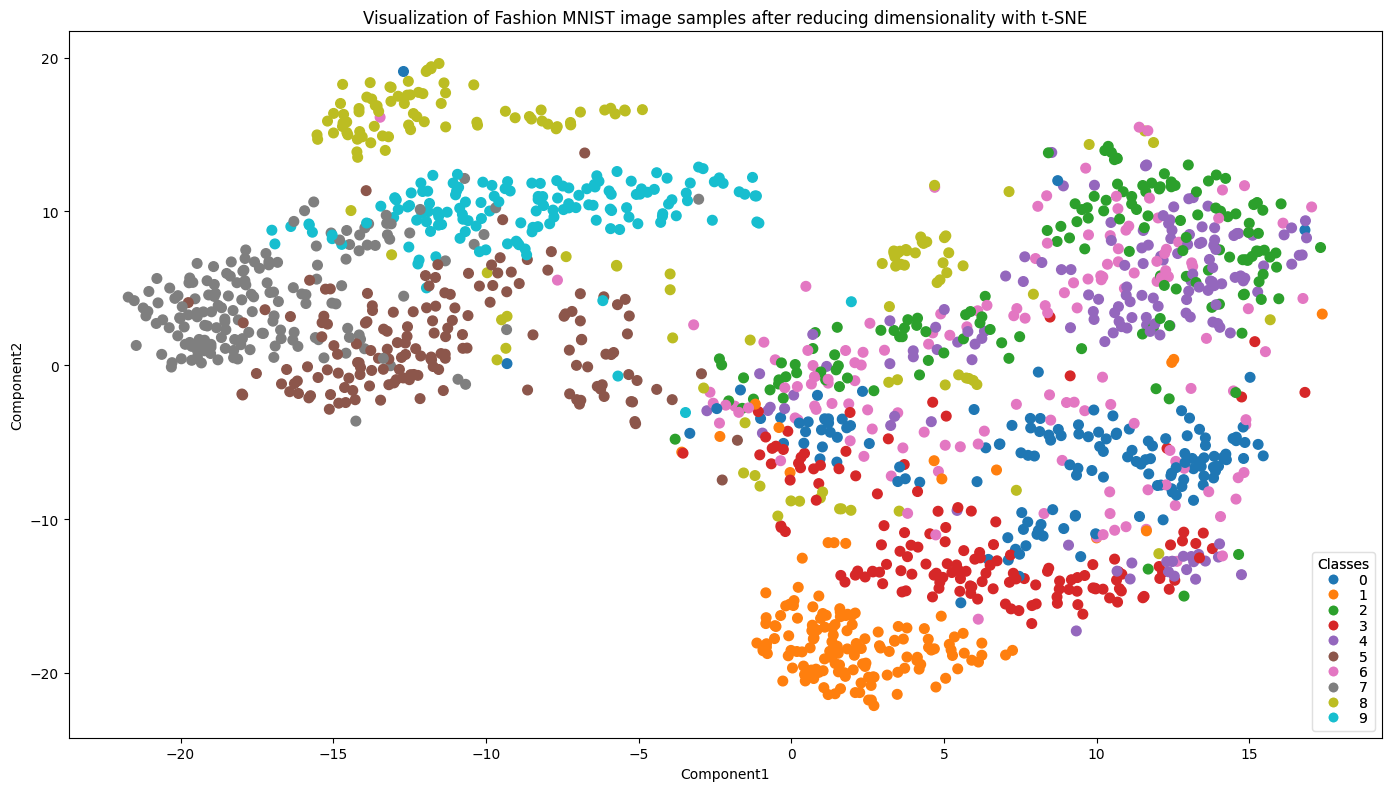

In [18]:
from radnn.plots import MultiScatterPlot

sPlotFileName = oFileSys.models.file(f"{sDataName}_2D_visualization_with_{sDimReductionMethod}.png")

oMultiPlot = MultiScatterPlot(f"Visualization of {sDataName} image samples after reducing dimensionality with {sDimReductionMethod}")
oMultiPlot.add_data("", nReducedSamples, nLabels)
oMultiPlot.prepare(0, "Component1", "Component2").save(sPlotFileName).show()
#oMultiPlot.save(sPlotFileName).show()

#from mllib.visualization import CMultiScatterPlot

#oPlot = CMultiScatterPlot("Visualization of %s image samples after reducing dimensionality with %s" % (sDataName, sDimReductionMethod))
#oPlot.AddData("",nReducedSamples , nLabels)
#oPlot.Show(0, "Component1", "Component2")

# Training
Learn a k-Means clustering model. with 10 clusters



In [19]:
from sklearn.cluster import KMeans

# _____// Clustering Hyperparameters \\_____
NUM_RUNS_RANDOM_CENTROIDS = 4
RANDOM_SEED               = 2021
CLUSTER_COUNT_K           = 10
#CLUSTER_COUNT_K           = 20
#CLUSTER_COUNT_K           = 50

nReducedSamples = nReducedSamples.astype(np.float64)
oClusteringModel = KMeans(init="k-means++", n_clusters=CLUSTER_COUNT_K, n_init=NUM_RUNS_RANDOM_CENTROIDS, verbose=2)
oClusteringModel.fit(nReducedSamples)

Initialization complete
Iteration 0, inertia 26347.56865665424.
Iteration 1, inertia 22546.965043579123.
Iteration 2, inertia 22246.574540987265.
Iteration 3, inertia 22099.68060340719.
Iteration 4, inertia 22038.67864408712.
Iteration 5, inertia 22008.353834169953.
Iteration 6, inertia 21983.780387225466.
Iteration 7, inertia 21967.652384080397.
Iteration 8, inertia 21941.802771627597.
Iteration 9, inertia 21906.588162146938.
Iteration 10, inertia 21747.869403386427.
Iteration 11, inertia 21338.952896960847.
Iteration 12, inertia 21080.868927766995.
Iteration 13, inertia 20989.533704511505.
Iteration 14, inertia 20938.521906999875.
Iteration 15, inertia 20902.960303797194.
Iteration 16, inertia 20878.08119695179.
Iteration 17, inertia 20869.430311838973.
Iteration 18, inertia 20867.193383458918.
Converged at iteration 18: center shift 0.005821266540842852 within tolerance 0.010601444683158174.
Initialization complete
Iteration 0, inertia 29981.861576958534.
Iteration 1, inertia 21658.

KMeans(n_clusters=10, n_init=4, verbose=2)

# Visualization of Clusters
Visualize the cluster centroids and partitioning of the 2D representation space of an image (after dimensionality reduction) using a Voronoi diagram.

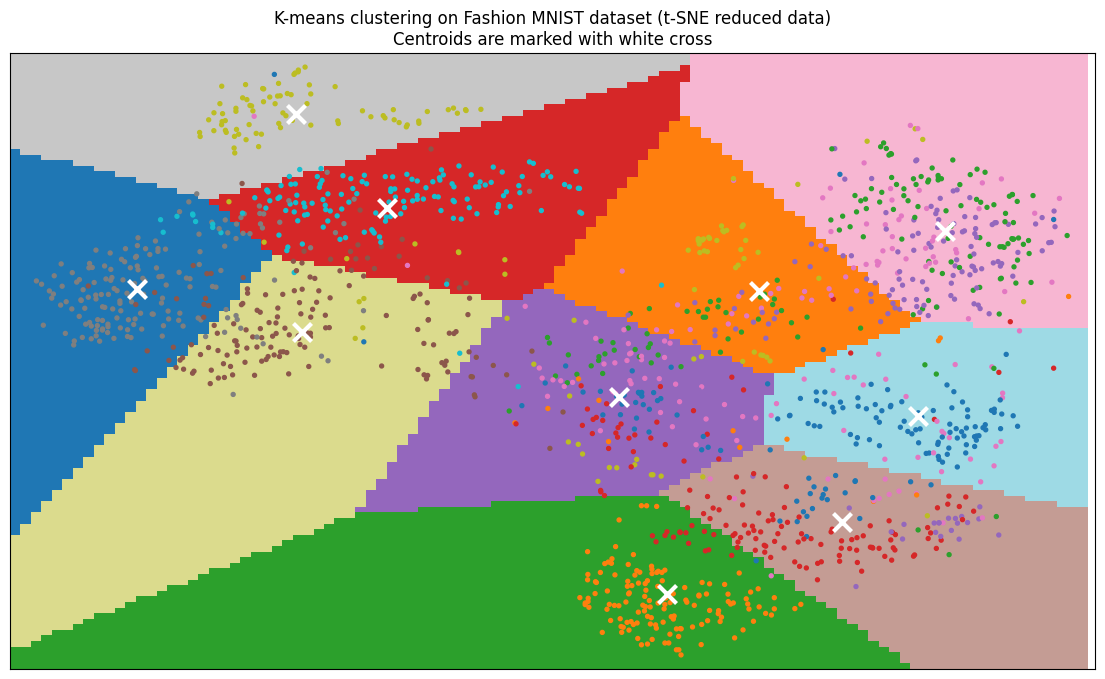

In [20]:
from radnn.plots import PlotVoronoi2D

sPlotFileName = oFileSys.models.file(f"{sDataName}_{CLUSTER_COUNT_K}_clusters.png")

oVoronoi = PlotVoronoi2D(nReducedSamples, nLabels, ground_truth_cluster_count=10,
                         title=f"K-means clustering on {sDataName} "
                         + f"dataset ({sDimReductionMethod} reduced data)\n"
                         + f"Centroids are marked with white cross")
oVoronoi.prepare_for_kmeans(oClusteringModel)
oVoronoi.save(sPlotFileName).show()